# Complex Avoided Crossing Examples

This notebook shows how to run fewest switches surface hopping (FSSH) on the three complex avoided crossing models (A, B and C) with two momentum rescaling directions:

* **D_min** (default): the gauge-fixed direction of Krotz and Tempelaar, Phys. Rev. A 109, 032210 (2024). The models use it with no extra step.
* **R_max**: the direction of Miao, Bellonzi and Subotnik, The Journal of chemical physics 150.12 (2019). You choose it by adding one ingredient to the model.

The models have a complex Hamiltonian, so FSSH uses `gauge_fixing="phase_overlap"` and the Berry (pseudomagnetic) force, `use_gauge_field_force=True`.

The wavepacket starts on diabat n = 0. We plot the transmitted part (x > 1) against the initial momentum p_x for:

* the population ρ_nn on each diabat n = 0, 1,
* the mean momenta p^x_n and p^y_n on each diabat.

We use only 100 trajectories, but you can change this parameter.

### Setup

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from qclab import Simulation, functions # import simulation class and helper functions
from qclab.models import (
    ComplexAvoidedCrossingA,
    ComplexAvoidedCrossingB,
    ComplexAvoidedCrossingC,
) # import model classes
from qclab.algorithms import FewestSwitchesSurfaceHopping # import algorithm class
from qclab.dynamics import serial_driver # import dynamics driver

We add one collect task to FSSH. It saves the population of each diabat for the trajectories with x > 1, and the same population times the momentum.

In [11]:
def collect_transmitted(sim, state, parameters):
    m = sim.model.constants.classical_coordinate_mass
    h = sim.model.constants.classical_coordinate_weight
    q = functions.z_to_q(state["z"], m, h)
    p = functions.z_to_p(state["z"], m, h)
    transmitted = q[:, 0] > 1.0
    pop = np.real(np.einsum("tii->ti", state["dm_db"])) * transmitted[:, np.newaxis]
    state["output_dict"]["trans_pop"] = pop
    state["output_dict"]["trans_pop_p"] = pop[:, :, np.newaxis] * p[:, np.newaxis, :]
    return state, parameters

`run_scan` runs FSSH for several initial momenta and returns the transmitted observables at the final time. If you give it a `rescaling_direction`, it replaces the default D_min direction of the model.

In [12]:
p_x_values = np.array([8.0, 12.0, 16.0, 20.0, 24.0])


def run_scan(model_class, constants, rescaling_direction=None):
    results = {"pop": [], "p_x": [], "p_y": []}
    for p_x in p_x_values:
        tmax = np.round(13.5 / p_x, 3)
        sim = Simulation()
        sim.settings.num_trajs = 100
        sim.settings.batch_size = 100
        sim.settings.tmax = tmax
        sim.settings.dt_collect = tmax / 10
        sim.settings.dt_update = tmax / 3000
        sim.settings.progress_bar = False

        sim.model = model_class({**constants, "init_momentum_x": p_x})
        if rescaling_direction is not None:
            sim.model.ingredients.append(("rescaling_direction_fssh", rescaling_direction))

        sim.algorithm = FewestSwitchesSurfaceHopping({
            "gauge_fixing": "phase_overlap",
            "use_gauge_field_force": True,
        })
        sim.algorithm.collect_recipe = sim.algorithm.collect_recipe + [collect_transmitted]

        sim.initial_state["wf_db"] = np.array([1, 0], dtype=complex)

        data = serial_driver(sim)

        pop = data.data_dict["trans_pop"][-1]
        pop_p = data.data_dict["trans_pop_p"][-1]
        with np.errstate(invalid="ignore", divide="ignore"):
            mean_p = pop_p / pop[:, np.newaxis] # mean momentum on each diabat
        results["pop"].append(pop)
        results["p_x"].append(mean_p[:, 0])
        results["p_y"].append(mean_p[:, 1])
    return {key: np.array(val) for key, val in results.items()}

`plot_observables` draws the three panels of the paper figures. Solid lines are D_min and dashed lines are R_max.

In [13]:
def plot_observables(dmin, rmax, title):
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
    labels = {"pop": r"$\rho_{nn}$", "p_x": r"$p^x_n$", "p_y": r"$p^y_n$"}
    for ax, key in zip(axes, ["pop", "p_x", "p_y"]):
        for n, color in [(0, "tab:blue"), (1, "tab:red")]:
            ax.plot(p_x_values, dmin[key][:, n], "o-", color=color, label=f"n = {n}, D_min")
            ax.plot(p_x_values, rmax[key][:, n], "s--", color=color, label=f"n = {n}, R_max")
        ax.set_xlabel(r"initial $p_x$")
        ax.set_ylabel(labels[key])
    axes[0].legend(fontsize=8)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

### Model A (W = 2.0)

The default rescaling direction of every model is D_min:

In [14]:
model = ComplexAvoidedCrossingA()
rescaling_direction, _ = model.get("rescaling_direction_fssh")
print(rescaling_direction.__name__)

rescaling_direction_fssh_dmin_complex_avoided_crossing_a


For model A, D_min always points along x. R_max points along y near the crossing.

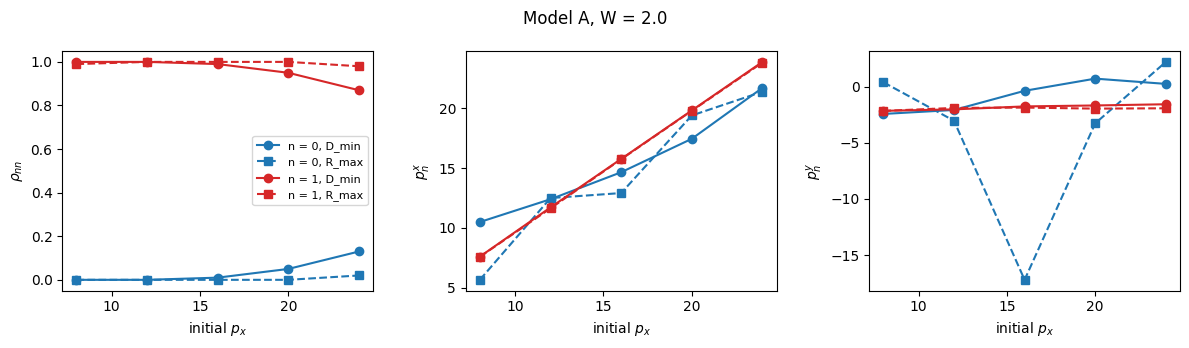

In [15]:
constants = {"W": 2.0}

dmin = run_scan(ComplexAvoidedCrossingA, constants)
rmax = run_scan(
    ComplexAvoidedCrossingA,
    constants,
    rescaling_direction=ComplexAvoidedCrossingA.rescaling_direction_fssh_rmax_complex_avoided_crossing_a,
)

plot_observables(dmin, rmax, "Model A, W = 2.0")

### Model B (W = 0.0)

With W = 0 the Hamiltonian is real. Then D_min and R_max are the same direction, so the solid and dashed lines are on top of each other.

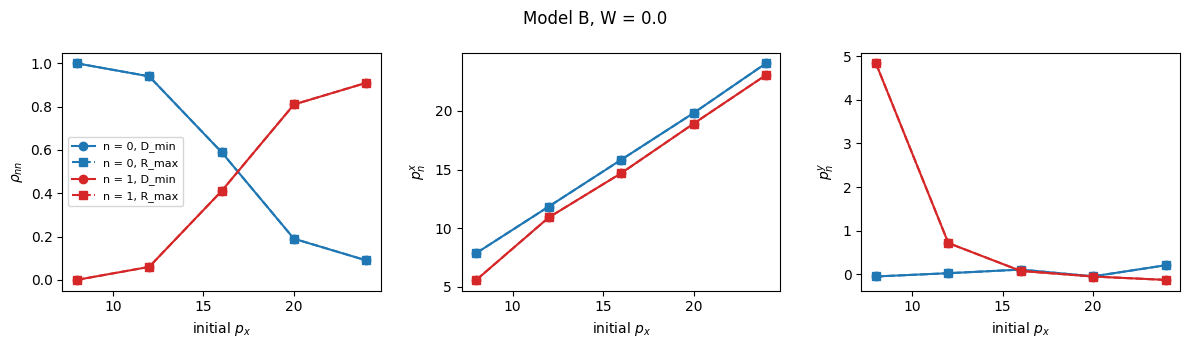

In [16]:
constants = {"W": 0.0}

dmin = run_scan(ComplexAvoidedCrossingB, constants)
rmax = run_scan(
    ComplexAvoidedCrossingB,
    constants,
    rescaling_direction=ComplexAvoidedCrossingB.rescaling_direction_fssh_rmax_complex_avoided_crossing_b,
)

plot_observables(dmin, rmax, "Model B, W = 0.0")

### Model C (W = 1.5)

Model C has a phase that depends on both x and y, so the two directions differ again.

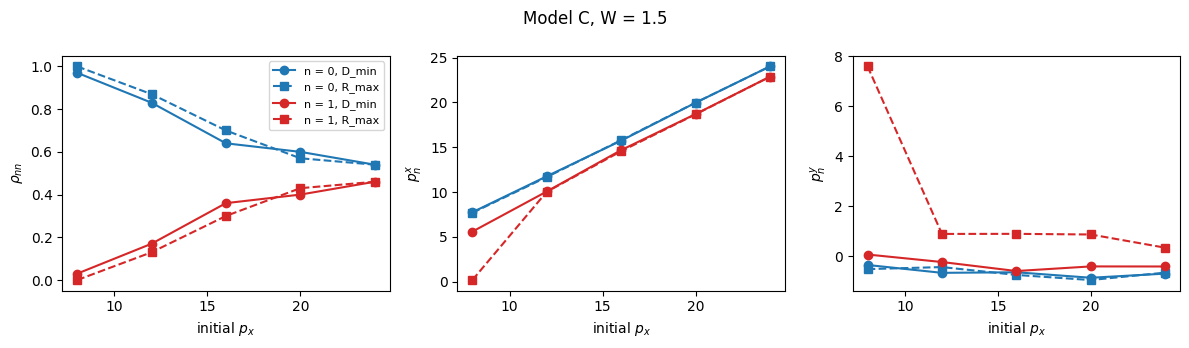

In [17]:
constants = {"W": 1.5}

dmin = run_scan(ComplexAvoidedCrossingC, constants)
rmax = run_scan(
    ComplexAvoidedCrossingC,
    constants,
    rescaling_direction=ComplexAvoidedCrossingC.rescaling_direction_fssh_rmax_complex_avoided_crossing_c,
)

plot_observables(dmin, rmax, "Model C, W = 1.5")